# Credit Card Fraud Detection

**Name:** Pratiksha Somnath Avhad  
**Internship:** Oasis Infobyte Data Analytics Internship  
**Level:** Level 2  
**Task:** Task 3 – Fraud Detection

## Objective
To detect fraudulent credit card transactions using Exploratory Data Analysis (EDA) and Machine Learning techniques.

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Loading the Dataset

df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Observation:
- The dataset contains 284,807 rows and 31 columns.
- It includes transaction details such as Time, Amount, and Class.
- The Class column indicates whether a transaction is legitimate (0) or fraudulent (1).
- The dataset was loaded successfully for further analysis.

In [3]:
# Checking Dataset Information

print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

### Observation:
- The dataset contains 284,807 entries and 31 columns.
- All columns have 284,807 non-null values, indicating no missing values.
- There are 30 columns with float64 data type and one column (`Class`) with int64 data type.
- The dataset uses approximately 67.4 MB of memory.

In [4]:
# Checking Missing Values and Duplicate Records

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing Values: 0
Duplicate Rows: 1081


### Observation:
- The dataset contains no missing values.
- A total of 1,081 duplicate rows were identified.
- Duplicate records should be handled before proceeding with further analysis and model training.

In [5]:
# Removing Duplicate Records

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Duplicate Rows Remaining:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (283726, 31)
Duplicate Rows Remaining: 0


### Observation:
- A total of 1,081 duplicate rows were removed from the dataset.
- The dataset now contains 283,726 rows and 31 columns.
- No duplicate rows remain in the dataset.
- The cleaned dataset is ready for further analysis.

In [6]:
# Checking Transaction Class Distribution

print("Transaction Class Counts:")
print(df["Class"].value_counts())

print("\nTransaction Class Percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(3))

Transaction Class Counts:
Class
0    283253
1       473
Name: count, dtype: int64

Transaction Class Percentages:
Class
0    99.833
1     0.167
Name: proportion, dtype: float64


### Observation:
- The dataset contains 283,253 legitimate transactions (Class 0).
- There are 473 fraudulent transactions (Class 1).
- Legitimate transactions account for 99.833% of the dataset, while fraudulent transactions account for only 0.167%.
- The dataset is highly imbalanced, which must be considered during model training and evaluation.

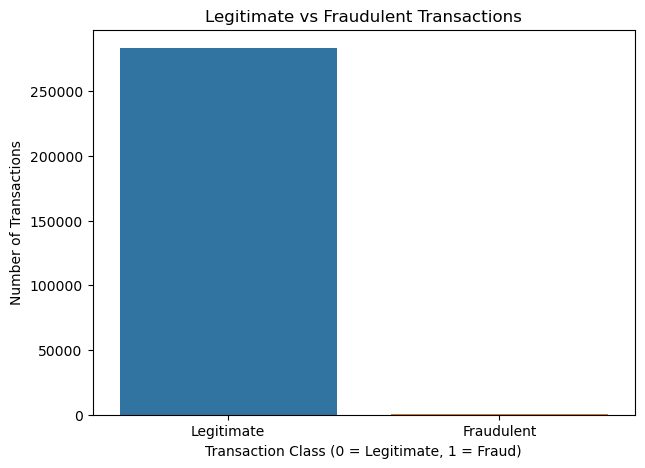

In [7]:
# Visualizing Transaction Class Distribution

plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

### Observation:
- The bar chart shows a significant difference between legitimate and fraudulent transactions.
- Legitimate transactions greatly outnumber fraudulent transactions.
- This visualization confirms that the dataset is highly imbalanced.
- Appropriate evaluation metrics will be important when building the fraud detection model.

In [8]:
# Statistical Summary of the Dataset

df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


### Observation:
- The statistical summary provides the count, mean, standard deviation, minimum, maximum, and quartile values of numerical columns.
- The average transaction amount is approximately 88.47.
- Transaction amounts vary significantly, with a maximum value of 25,691.16.
- The mean of the Class column is approximately 0.001667, reflecting the very small proportion of fraudulent transactions.

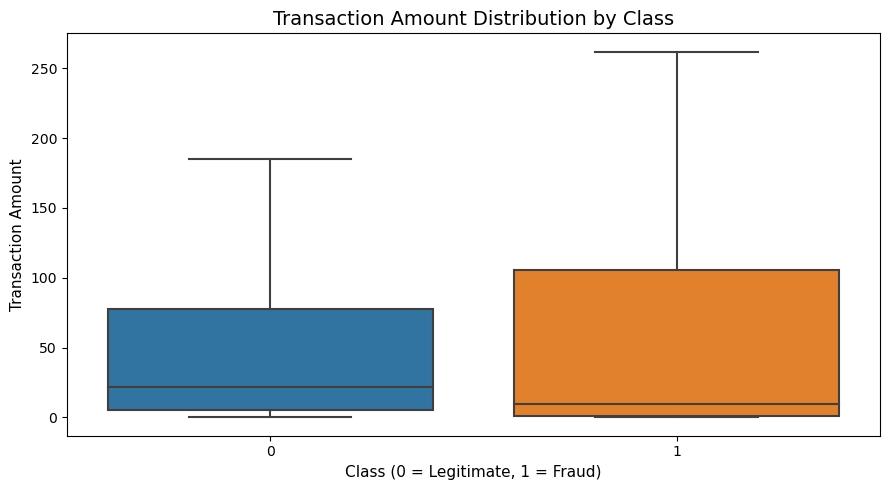

In [10]:
# Comparing Transaction Amounts by Class

plt.figure(figsize=(9, 5))

sns.boxplot(
    x="Class",
    y="Amount",
    data=df,
    showfliers=False
)

plt.title("Transaction Amount Distribution by Class", fontsize=14)
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)", fontsize=11)
plt.ylabel("Transaction Amount", fontsize=11)
plt.tight_layout()
plt.show()

### Observation:
- The boxplot compares transaction amounts for legitimate and fraudulent transactions.
- Both classes show variation in transaction amounts.
- The transaction amount distributions overlap, so Amount alone may not be sufficient to identify fraudulent transactions.
- Extreme values are hidden in the visualization to make the main distribution easier to compare.

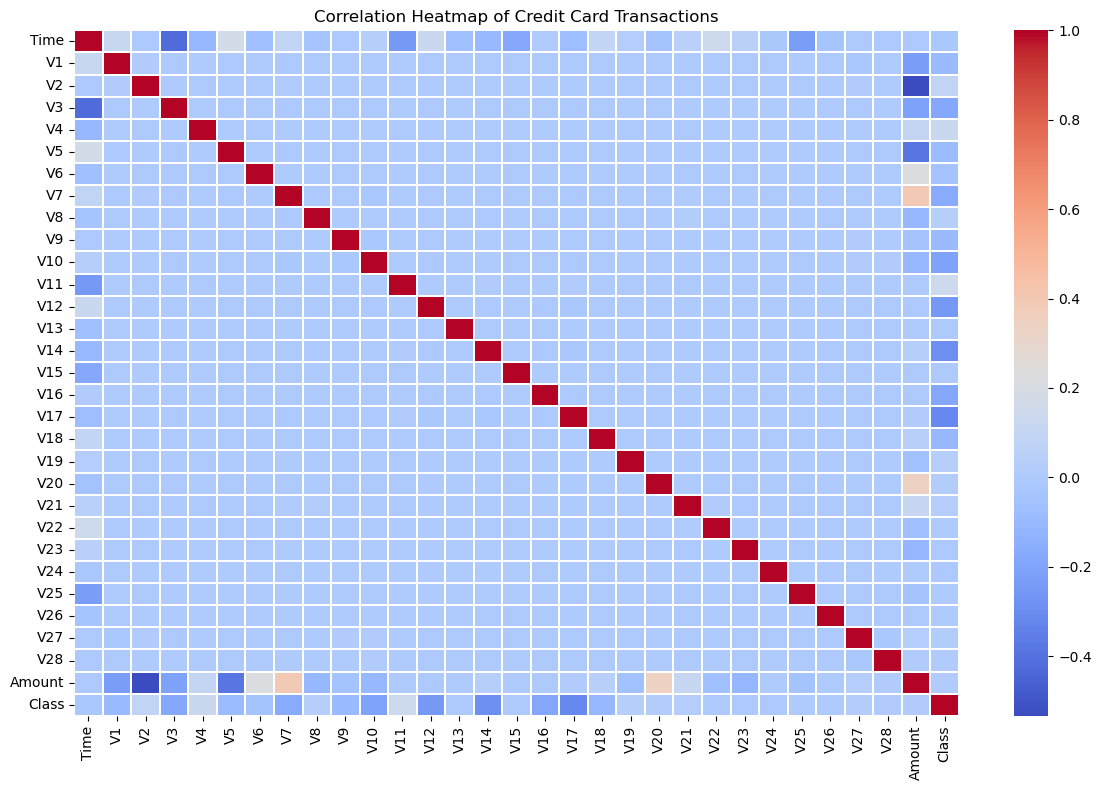

In [11]:
# Correlation Analysis

correlation = df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    linewidths=0.1
)

plt.title("Correlation Heatmap of Credit Card Transactions")
plt.tight_layout()
plt.show()

### Observation:
- The heatmap shows the correlation between numerical features in the dataset.
- Most features have weak linear correlations with one another.
- The correlation between individual features and the target Class can help us understand potential patterns in fraudulent 
  transactions.
- Multiple features should be considered together when building the fraud detection model.

In [12]:
# Separating Features and Target

X = df.drop("Class", axis=1)
y = df["Class"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (283726, 30)
Target Shape: (283726,)


### Observation:
- The dataset contains 283,726 records and 30 input features.
- The target variable (`Class`) contains the transaction labels.
- The input features (`X`) and target variable (`y`) have been separated successfully.
- The data is ready to be split into training and testing sets.

In [13]:
# Splitting Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features Shape: (226980, 30)
Testing Features Shape: (56746, 30)

Training Target Distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing Target Distribution:
Class
0    56651
1       95
Name: count, dtype: int64


### Observation:
- The dataset was split into 80% training data and 20% testing data.
- The training set contains 226,980 records, while the testing set contains 56,746 records.
- The training set contains 378 fraudulent transactions, and the testing set contains 95 fraudulent transactions.
- Stratified splitting preserves the class distribution across both sets.
- The dataset remains highly imbalanced, so precision, recall, F1-score, and the confusion matrix will be important for 
  model evaluation.

In [14]:
# Training the Logistic Regression Model

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Observation:
- The Logistic Regression model was trained successfully using the training dataset.
- The `class_weight="balanced"` parameter was used to account for the imbalance between legitimate and fraudulent transactions.
- The trained model is ready to predict fraudulent transactions on the testing dataset.
- Model performance will be evaluated using precision, recall, F1-score, and a confusion matrix.

In [15]:
# Predicting Fraudulent Transactions

y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

Predictions completed successfully!

First 10 Actual Labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 Predicted Labels:
[0 0 0 0 0 0 0 0 0 0]


### Observation:
- The trained Logistic Regression model successfully generated predictions for the testing dataset.
- The first 10 actual labels are all 0, representing legitimate transactions.
- The first 10 predicted labels are also 0, matching the actual labels.
- Overall model performance must be evaluated on the complete testing dataset because the first 10 predictions alone are not
  sufficient to assess accuracy.

In [16]:
# Evaluating the Model

from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

print("Confusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

           0     0.9998    0.9652    0.9822     56651
           1     0.0409    0.8842    0.0782        95

    accuracy                         0.9651     56746
   macro avg     0.5203    0.9247    0.5302     56746
weighted avg     0.9982    0.9651    0.9807     56746

Confusion Matrix:

[[54681  1970]
 [   11    84]]


### Observation:
- The Logistic Regression model achieved an overall accuracy of 96.51%.
- The model correctly identified 84 out of 95 fraudulent transactions, achieving a fraud recall of 88.42%.
- The fraud precision is 4.09%, indicating that many transactions predicted as fraudulent were actually legitimate.
- The confusion matrix shows 84 true positives, 11 false negatives, 1,970 false positives, and 54,681 true negatives.
- Although the model identifies most fraudulent transactions, the high number of false positives indicates that further model 
  improvement is needed.
- Precision, recall, and F1-score are important evaluation metrics because the dataset is highly imbalanced.

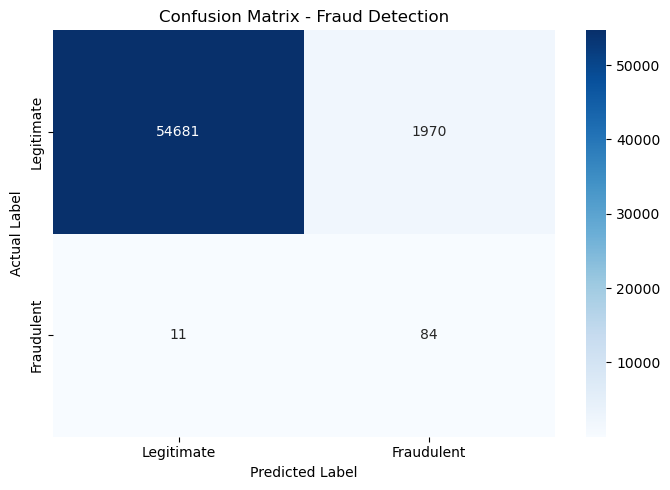

In [17]:
# Visualizing the Confusion Matrix

plt.figure(figsize=(7, 5))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Confusion Matrix - Fraud Detection")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Observation:
- The confusion matrix heatmap visually represents the model's classification results.
- The model correctly classified 54,681 legitimate transactions and 84 fraudulent transactions.
- It incorrectly classified 1,970 legitimate transactions as fraudulent.
- It failed to identify 11 fraudulent transactions.
- The heatmap highlights the need to reduce false positives while maintaining good fraud detection performance.

In [18]:
# Model Performance Summary

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Model Performance Summary")
print("-" * 30)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

Model Performance Summary
------------------------------
Accuracy:  0.9651
Precision: 0.0409
Recall:    0.8842
F1-Score:  0.0782


### Observation:
- The Logistic Regression model achieved an accuracy of 96.51%.
- The precision for fraudulent transactions is 4.09%, indicating a high number of false positive predictions.
- The recall is 88.42%, meaning the model identified most of the fraudulent transactions in the testing dataset.
- The F1-score is 7.82%, reflecting the trade-off between precision and recall.
- Since the dataset is highly imbalanced, accuracy alone is not sufficient to judge model performance.
- Further improvements are needed to reduce false positives while maintaining strong fraud detection recall.

In [19]:
# Training a Random Forest Model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Observation:
- The Random Forest classifier was trained successfully using the training dataset.
- The `class_weight="balanced"` parameter was used to account for class imbalance.
- The model uses 100 decision trees to make predictions.
- The trained model is ready for evaluation on the testing dataset.

In [20]:
# Predicting Fraudulent Transactions Using Random Forest

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Labels:")
print(rf_pred[:10])

Random Forest predictions completed successfully!

First 10 Actual Labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 Predicted Labels:
[0 0 0 0 0 0 0 0 0 0]


### Observation:
- The Random Forest model successfully generated predictions for the testing dataset.
- The first 10 actual labels are all 0, representing legitimate transactions.
- The first 10 predicted labels are also 0, matching the actual labels.
- The model's overall performance will be evaluated using the classification report and confusion matrix.

In [21]:
# Evaluating the Random Forest Model

print("Random Forest Classification Report:\n")
print(classification_report(y_test, rf_pred, digits=4))

print("Random Forest Confusion Matrix:\n")
print(confusion_matrix(y_test, rf_pred))

Random Forest Classification Report:

              precision    recall  f1-score   support

           0     0.9995    1.0000    0.9997     56651
           1     0.9710    0.7053    0.8171        95

    accuracy                         0.9995     56746
   macro avg     0.9853    0.8526    0.9084     56746
weighted avg     0.9995    0.9995    0.9994     56746

Random Forest Confusion Matrix:

[[56649     2]
 [   28    67]]


### Observation:
- The Random Forest model achieved an overall accuracy of 99.95%.
- The model achieved 97.10% precision for fraudulent transactions, indicating that most transactions predicted as fraudulent
  were actually fraudulent.
- The fraud recall is 70.53%, meaning the model identified 67 out of 95 fraudulent transactions.
- The confusion matrix shows 56,649 true negatives, 2 false positives, 28 false negatives, and 67 true positives.
- Compared with Logistic Regression, Random Forest produced far fewer false positives and a higher fraud F1-score.
- However, the model missed 28 fraudulent transactions, so further evaluation may be useful before selecting the final model.

In [22]:
# Comparing Logistic Regression and Random Forest

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ]
})

print("Model Comparison:")
display(comparison.round(4))

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9651,0.0409,0.8842,0.0782
1,Random Forest,0.9995,0.9710,0.7053,0.8171


### Observation:
- The comparison shows that Random Forest achieved an accuracy of 99.95% and an F1-score of 81.71%.
- Logistic Regression achieved a higher fraud recall of 88.42%, compared with 70.53% for Random Forest.
- Random Forest achieved much higher fraud precision (97.10%) than Logistic Regression (4.09%).
- Random Forest produced fewer false positives,while Logistic Regression identified larger proportion of fraudulent transactions.
- Overall, Random Forest provides a better balance between precision and recall for this experiment, although it misses more
  fraudulent transactions than Logistic Regression.
- The final model choice depends on whether reducing false alarms or detecting as many fraudulent transactions as possible is 
  the main priority.

In [23]:
# Analyzing Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10).round(4))

Top 10 Important Features:


,Feature,Importance
14,V14,0.1859
10,V10,0.1204
12,V12,0.1003
17,V17,0.0940
4,V4,0.0923
3,V3,0.0597
16,V16,0.0562
11,V11,0.0536
2,V2,0.0356
9,V9,0.0258


### Observation:
- Feature importance analysis identifies the variables that contributed most to the Random Forest model's predictions.
- V14 is the most important feature, with an importance score of 0.1859.
- V10, V12, V17, and V4 are also among the top important features.
- These results show that several transaction-related features contribute to the model's fraud detection predictions.
- Feature importance indicates the model's relative reliance on each feature; it does not establish a causal relationship 
  with fraud.

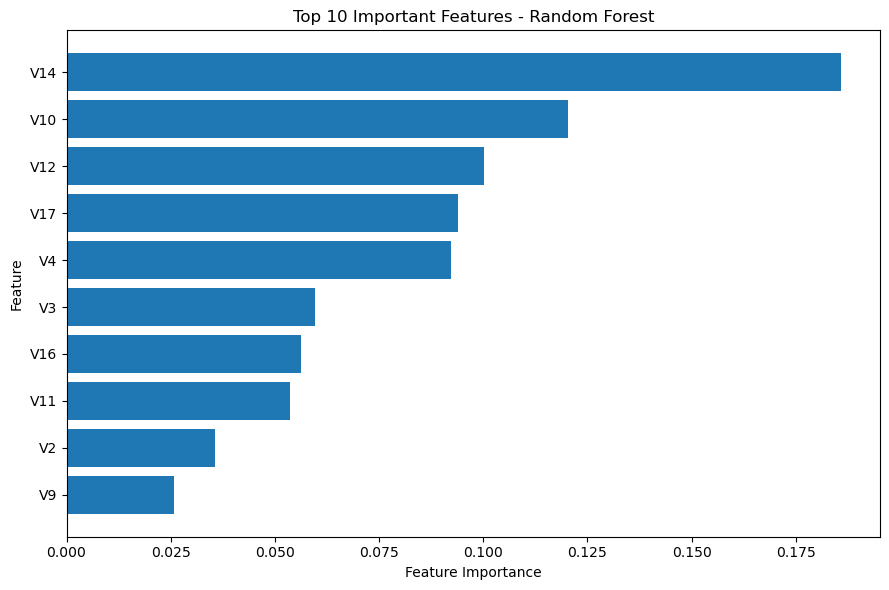

In [24]:
# Visualizing Top 10 Important Features

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Observation:
- The bar chart visualizes the top 10 features ranked by their importance in the Random Forest model.
- V14 has the highest feature importance, followed by V10, V12, V17, and V4.
- The chart makes it easier to compare the relative contribution of the selected features to the model's predictions.
- These importance scores describe the model's behavior and do not prove that any feature causes fraudulent transactions.

## Final Conclusion

The Credit Card Fraud Detection project explored transaction data to identify potentially fraudulent activities. 
The dataset was cleaned by removing duplicate records and analyzed using visualizations and statistical summaries.

Two machine learning models, Logistic Regression and Random Forest, were trained and evaluated. Logistic Regression achieved a
fraud recall of 88.42%, while Random Forest achieved a fraud precision of 97.10% and an F1-score of 81.71%.

Random Forest provided a better balance between precision and recall in this experiment, although it missed some fraudulent 
transactions. The comparison also highlighted the importance of evaluating precision, recall, and F1-score rather than relying 
on accuracy alone when working with highly imbalanced data.

Finally, feature importance analysis identified V14, V10, and V12 among the most important features used by the Random Forest 
model. This project provided practical experience in data cleaning, exploratory data analysis, machine learning,
model evaluation, and fraud detection.